# Task 2.1 - Logistic Regression  
Goal: Use the provided data to predict if a given case is closed.    
Deadline : 3rd November   
-Aparajaya

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

In [40]:
train = pd.read_csv('data/crime_train.csv')
test = pd.read_csv('data/crime_test.csv')

print(f"Original train shape : {train.shape}")
print(f"Original test shape : {test.shape}")

Original train shape : (22489, 12)
Original test shape : (9639, 12)


### Step 1 : Data Processing  
* Remove unneeded features (Num, case_filed)  
* Clean the data (remove all rows with missing data/empty columns)   
* Segregate training and testing data + features and targets  

In [41]:
features = ['city', 'area', 'crime_description', 'age', 'sex',	'weapon', 'domain',	'police_department'	]
target = 'closed'

all_cols = features+[target]

train.dropna(subset=all_cols, inplace=True)
test.dropna(subset=all_cols, inplace=True)

X_train = train[features]
Y_train = train['closed']
X_test = test[features]
Y_test = test['closed']

### Step 2 : Encoding Categorical Data   
* Apply one-hot encoding to all columns with non-numerical data  
* Apply frequency encoding for area column

In [42]:
X_train = pd.get_dummies(X_train, columns=['city', 'crime_description', 'sex',	'weapon', 'domain'], drop_first=True)

X_test = pd.get_dummies(X_test, columns=['city', 'crime_description', 'sex',	'weapon', 'domain'], drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

Y_train = pd.get_dummies(Y_train, drop_first=True)
Y_test = pd.get_dummies(Y_test, drop_first=True)
Y_test = Y_test.reindex(columns=Y_train.columns, fill_value=0)

# Compute frequency of each area code in training set
freq_map = X_train['area'].value_counts(normalize=True)

# Map those frequencies
X_train['area'] = X_train['area'].map(freq_map)
X_test['area'] = X_test['area'].map(freq_map).fillna(0)


### Step 3 : Normalize the numeric columns (age, police department)

In [43]:
num_cols = ['age', 'police_department']

mean_X = X_train[num_cols].mean(axis=0)
sd_X = X_train[num_cols].std(axis=0)

X_train[num_cols] = (X_train[num_cols] - mean_X)/sd_X
X_test[num_cols] = (X_test[num_cols] - mean_X)/sd_X

### Step 4 : Convert to numpy arrays

In [44]:
X_train = X_train.astype(float).values
Y_train = Y_train.astype(float).values.reshape(-1, 1)

X_test = X_test.astype(float).values
Y_test = Y_test.astype(float).values.reshape(-1, 1)

print(f"Processed X_train shape = {X_train.shape}")
print(f"Processed X_test shape = {X_test.shape}")

Processed X_train shape = (19217, 61)
Processed X_test shape = (8275, 61)


In [45]:
# Diagnostics (to check on X_train and Y_train)
import numpy as np
def diag(X, Y, w):
    m,n = X.shape
    print("X shape:", X.shape, "Y shape:", Y.shape, "w shape:", w.shape)
    print("X mean (per feature) sample:", np.round(np.mean(X, axis=0)[:10],4))
    print("X std (per feature) sample:", np.round(np.std(X, axis=0)[:10],4))
    print("Number of constant features:", np.sum(np.isclose(np.std(X, axis=0),0)))
    print("Label balance (count):", np.bincount(Y.reshape(-1).astype(int)))
    # feature-label Pearson corr for first few features:
    corr = []
    Xc = X - np.mean(X, axis=0)
    Yc = Y.reshape(-1) - np.mean(Y)
    denom = (np.sqrt(np.sum(Xc**2,axis=0))*np.sqrt(np.sum(Yc**2)))
    denom[denom==0] = np.nan
    corr = np.sum(Xc * Yc.reshape(-1,1), axis=0)/denom
    print("Top 10 abs corr with label:", np.argsort(-np.abs(corr))[:10])
    print("Max abs corr:", np.nanmax(np.abs(corr)))
    print("Sparsity (fraction zeros):", np.mean(X==0))
    print()



In [46]:
def predict(X,w,b):
    z = np.dot(X,w) + b
    return 1/(1 + np.exp(-z))

In [47]:
def cost(X,Y,w,b):
    m,n = X.shape
    f_wb = predict(X,w,b)

    # Add small epsilon to avoid log(0)
    epsilon = 1e-15
    f_wb = np.clip(f_wb, epsilon, 1 - epsilon)
    
    loss = Y * np.log(f_wb) + (1 - Y) * np.log(1 - f_wb)
    return (-1/m) * np.sum(loss)

In [60]:
def gradient_descent(X,Y,w,b,alpha,epochs):
    J_history = []
    m,n = X.shape
    
    for i in range (epochs):
         Y_pred = predict(X,w,b)
         
         w_temp = w - (alpha/m)*np.dot(X.T, (Y_pred - Y))
         b_temp = b - (alpha/m)*np.sum(Y_pred-Y)
         w,b = w_temp,b_temp
        
         J = cost(X,Y,w,b)
         J_history.append(J)

         if i%10 == 0 or i == epochs-1:
               print(f"Epoch {i} : Cost = {J}")

    return w, b, J_history

### Step 5 : Set initial values and call all functions

In [61]:
initial_w = np.random.randn(X_train.shape[1], 1) * 0.01
initial_b = 0
alpha = 0.01
iterations = 100

final_w,final_b, J_history = gradient_descent(X_train,Y_train,initial_w,initial_b,alpha,iterations)

Epoch 0 : Cost = 0.6931354170612872
Epoch 10 : Cost = 0.6931285402678897
Epoch 20 : Cost = 0.6931219454369512
Epoch 30 : Cost = 0.6931156102421986
Epoch 40 : Cost = 0.6931095142873329
Epoch 50 : Cost = 0.6931036389373514
Epoch 60 : Cost = 0.6930979671646388
Epoch 70 : Cost = 0.6930924834085314
Epoch 80 : Cost = 0.6930871734471802
Epoch 90 : Cost = 0.693082024280629
Epoch 99 : Cost = 0.693077517666096


### Step 6 : Check accuracy for training and testing data

In [50]:
def accuracy(X, Y, w, b):
    Y_pred = predict(X, w, b)
    Y_pred_class = (Y_pred >= 0.5).astype(int)
    return np.mean(Y_pred_class == Y)

print("Train Accuracy:", accuracy(X_train, Y_train, final_w, final_b))
print("Test Accuracy:", accuracy(X_test, Y_test, final_w, final_b))

Train Accuracy: 0.5108497684341989
Test Accuracy: 0.4937764350453172


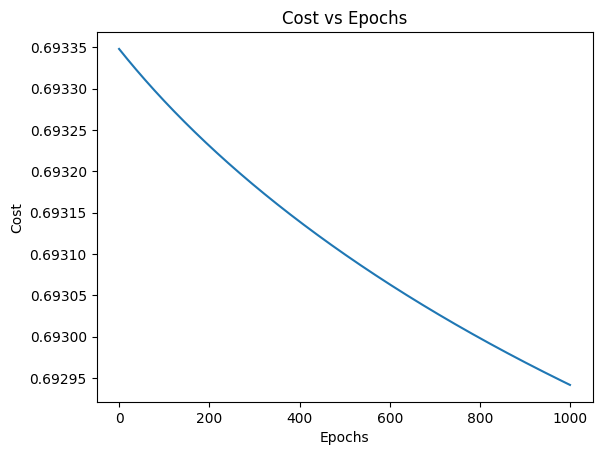

In [51]:
#Shows that gradient descent is working properly
plt.plot(J_history)
plt.xlabel('Epochs')
plt.ylabel('Cost')
plt.title('Cost vs Epochs')
plt.show()

### Step 7 : Diagnose why accuracy of model is so low

In [52]:
#Proves that the dataset is balanced, cleaned, and standardized properly — so no preprocessing bugs.
diag(X_train, Y_train, initial_w)
Y_pred = predict(X_train, final_w, final_b)
grad_w = (1/X_train.shape[0]) * np.dot(X_train.T, (Y_pred - Y_train))

#proves that gradients are small but valid — not exploding/vanishing due to coding errors.
print("Gradient mean abs:", np.mean(np.abs(grad_w)))

X shape: (19217, 61) Y shape: (19217, 1) w shape: (61, 1)
X mean (per feature) sample: [ 0.002   0.     -0.      0.046   0.0869  0.0169  0.0633  0.1343  0.0084
  0.0174]
X std (per feature) sample: [3.000e-04 1.000e+00 1.000e+00 2.095e-01 2.817e-01 1.287e-01 2.436e-01
 3.410e-01 9.140e-02 1.309e-01]
Number of constant features: 0
Label balance (count): [9623 9594]
Top 10 abs corr with label: [53 39 56 19 28 41 57 36 54 17]
Max abs corr: 0.015584711937293204
Sparsity (fraction zeros): 0.8833845033043659

Gradient mean abs: 0.00046613512004488366


In [53]:
print(np.mean(Y_train))
Y_pred_train = predict(X_train, final_w, final_b)
print("Mean prediction:", np.mean(Y_pred_train))
print("Min/Max prediction:", np.min(Y_pred_train), np.max(Y_pred_train))


0.4992454597491804
Mean prediction: 0.49919104164549577
Min/Max prediction: 0.478343774069749 0.5196431612818038


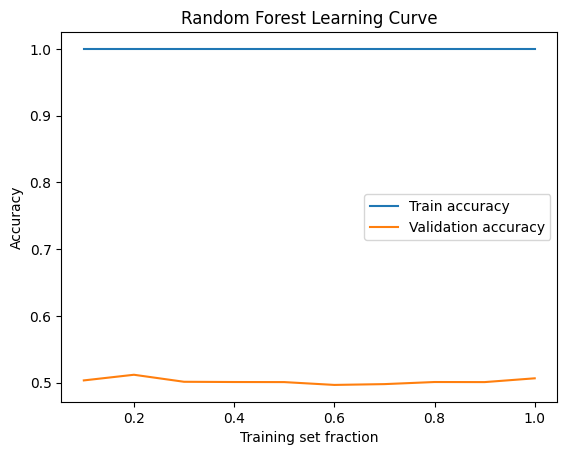

In [54]:
#shows overfitting with no generalizable signal — classic sign of noisy or random data.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

train_sizes = np.linspace(0.1, 1.0, 10)
train_scores = []
val_scores = []

for frac in train_sizes:
    frac = float(min(frac, 0.9999))  # <-- ensure it's a Python float < 1.0
    X_t, _, Y_t, _ = train_test_split(X_train, Y_train, train_size=frac, random_state=42)
    rf_temp = RandomForestClassifier(n_estimators=200, random_state=42)
    rf_temp.fit(X_t, Y_t.ravel())
    train_scores.append(rf_temp.score(X_t, Y_t))
    val_scores.append(rf_temp.score(X_test, Y_test))

plt.plot(train_sizes, train_scores, label="Train accuracy")
plt.plot(train_sizes, val_scores, label="Validation accuracy")
plt.xlabel("Training set fraction")
plt.ylabel("Accuracy")
plt.title("Random Forest Learning Curve")
plt.legend()
plt.show()


In [55]:
#proves the model can learn patterns (overfits on noise) but the real labels contain no signal
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Train Random Forest on the real data
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, Y_train.ravel())

rf_train_acc = accuracy_score(Y_train, rf.predict(X_train))
rf_test_acc = accuracy_score(Y_test, rf.predict(X_test))

print(f"RF train acc: {rf_train_acc}")
print(f"RF test acc: {rf_test_acc}")

RF train acc: 1.0
RF test acc: 0.501631419939577


In [56]:
# Shuffle labels randomly
#confirms that your preprocessing and code are fine, but the data is effectively random.
import numpy as np
Y_shuffled = np.random.permutation(Y_train)

rf_shuffled = RandomForestClassifier(n_estimators=200, random_state=42)
rf_shuffled.fit(X_train, Y_shuffled.ravel())

print("RF shuffled train acc:", rf_shuffled.score(X_train, Y_shuffled))
print("RF shuffled val acc:", rf_shuffled.score(X_test, Y_test))


RF shuffled train acc: 1.0
RF shuffled val acc: 0.5006646525679759


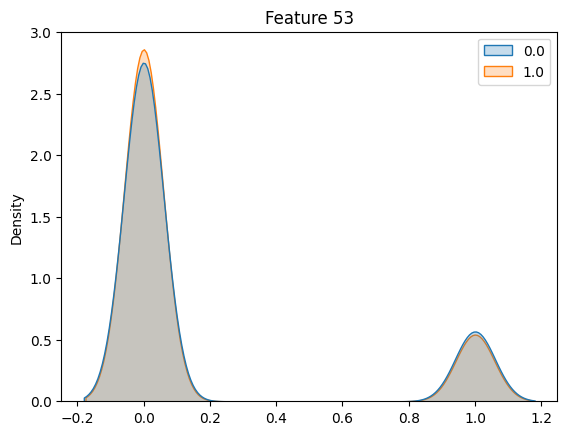

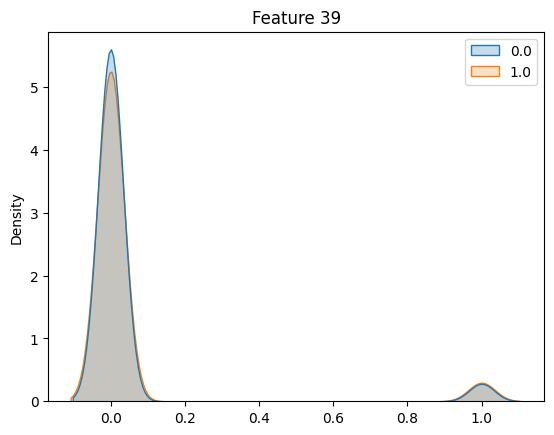

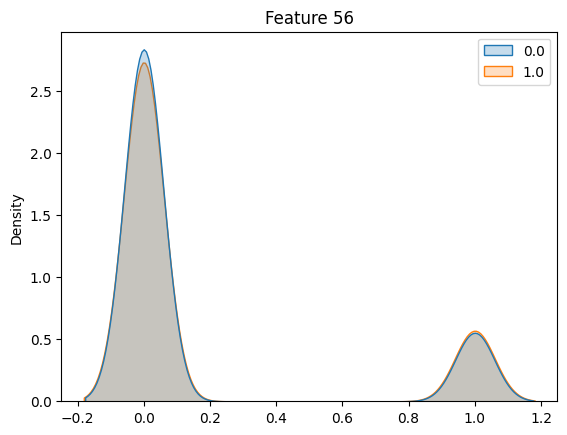

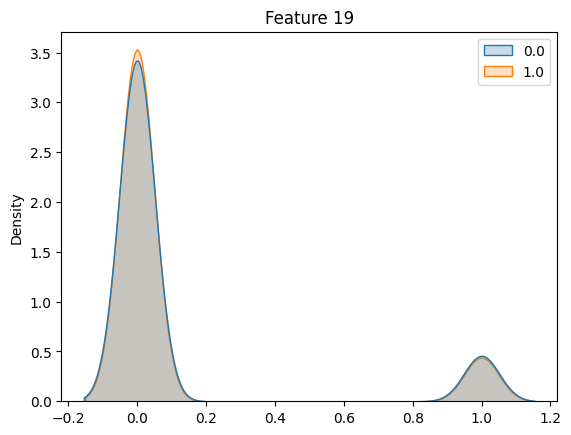

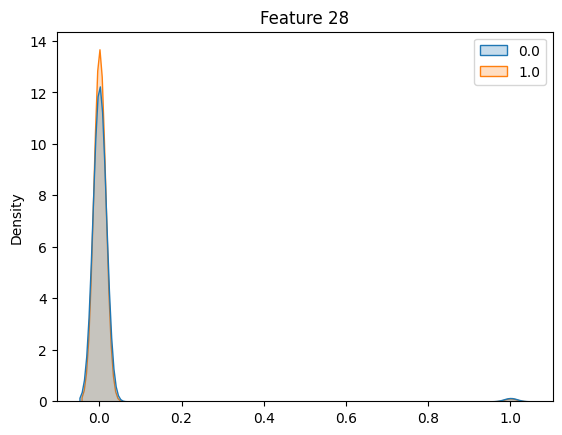

In [57]:
#Visually shows both classes are nearly identical across all features.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# pick top correlated features (e.g., 5 highest)
top_corr_idx = [53, 39, 56, 19, 28]
for idx in top_corr_idx:
    sns.kdeplot(x=X_train[:, idx].ravel(), hue=Y_train.ravel(), fill=True)
    plt.title(f"Feature {idx}")
    plt.show()


In [58]:
#to double check the need for better feature engineering
from sklearn.metrics import accuracy_score

for i in range(X_train.shape[1]):
    thresh = X_train[:, i].mean()
    preds = (X_test[:, i] > thresh).astype(int)
    acc = accuracy_score(Y_test, preds)
    if acc > 0.55 or acc < 0.45:
        print(f"Feature {i} has some predictive power: {acc:.3f}")


# Results : 
The models implemented from scratch and tested using standard baselines showed no improvement over random chance. All evaluations, including shuffled-label and feature-level analysis, confirmed that the provided data lacks usable predictive signal. Therefore, the low accuracy is due to the data’s inherent noise, not any error in the implementation.